In [32]:
from dataclasses import dataclass
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

@dataclass
class Population:
    """
    Diploid population.
    hap_counts has shape (N, 2):
        hap_counts[i, 0] = copy number of haplotype 1 in individual i
        hap_counts[i, 1] = copy number of haplotype 2 in individual i
    """
    hap_counts: np.ndarray

def initialize_population(N, mode="constant", rng=None, **kwargs):
    """
    Initialize a population under different starting distributions.

    Parameters
    ----------
    N : int
        Population size.
    mode : str
        One of {"constant", "gaussian", "poisson"}.
    rng : np.random.Generator
        Random number generator.
    kwargs :
        For constant: init_copies
        For gaussian: mean, sd
        For poisson: lam
    """
    if rng is None:
        rng = np.random.default_rng()

    if N <= 0:
        raise ValueError("N must be positive.")

    if mode == "constant":
        init_copies = kwargs.get("init_copies", 5)
        hap_counts = np.full((N, 2), init_copies, dtype=int)

    elif mode == "gaussian":
        mean = kwargs.get("mean", 10)
        sd = kwargs.get("sd", 2)
        hap_counts = rng.normal(loc=mean, scale=sd, size=(N, 2))
        hap_counts = np.round(hap_counts).astype(int)
        hap_counts[hap_counts < 1] = 1

    elif mode == "poisson":
        lam = kwargs.get("lam", 10)
        hap_counts = rng.poisson(lam=lam, size=(N, 2))
        hap_counts[hap_counts < 1] = 1

    else:
        raise ValueError(f"Unknown mode: {mode}")

    return Population(hap_counts=hap_counts)


def make_gamete(n1: int, n2: int, rec: float, rng: np.random.Generator) -> int:
    """
    Produce one gamete from a diploid parent carrying haplotypes
    with copy numbers n1 and n2.

    With probability 1-rec:
        inherit one haplotype unchanged.

    With probability rec:
        perform Otto-style recombination:
            choose breakpoints b1 in {1,...,n1}, b2 in {1,...,n2}
            then form either:
                b1 + (n2 - b2)
            or:
                b2 + (n1 - b1)

    Returns
    -------
    int
        Copy number in the gamete.
    """
    if n1 <= 0 or n2 <= 0:
        raise ValueError("Copy numbers must be positive integers.")
    if not (0.0 <= rec <= 1.0):
        raise ValueError("rec must be between 0 and 1.")

    # No recombination
    if rng.random() > rec:
        return n1 if rng.random() < 0.5 else n2

    # Recombination
    if rng.random() < 0.5:
        b1 = rng.integers(1, n1 + 1)  # inclusive of n1
        b2 = rng.integers(1, n2 + 1)  # inclusive of n2
        g = b1 + (n2 - b2)
    else:
        b2 = rng.integers(1, n2 + 1)
        b1 = rng.integers(1, n1 + 1)
        g = b2 + (n1 - b1)

    # In this model, gamete copy number should remain >= 1
    # because b1 and b2 are at least 1.
    if g <= 0:
        raise RuntimeError(f"Generated non-positive gamete copy number: {g}")

    return int(g)


def make_offspring(
    parent1: np.ndarray,
    parent2: np.ndarray,
    rec: float,
    rng: np.random.Generator
) -> np.ndarray:
    """
    Create one diploid offspring from two diploid parents.

    Each parent contributes one gamete.
    """
    if parent1.shape != (2,) or parent2.shape != (2,):
        raise ValueError("Each parent must be a length-2 array of haplotype copy numbers.")

    g1 = make_gamete(int(parent1[0]), int(parent1[1]), rec, rng)
    g2 = make_gamete(int(parent2[0]), int(parent2[1]), rec, rng)

    return np.array([g1, g2], dtype=int)


def evolve_one_generation(
    pop: Population,
    rec: float,
    rng: np.random.Generator | None = None
) -> Population:
    """
    Evolve the population by one generation under neutral
    Wright-Fisher sampling.

    For each offspring:
        - sample two parents uniformly from the current population
        - produce one gamete from each
        - combine them into a diploid offspring
    """
    if rng is None:
        rng = np.random.default_rng()

    hap = pop.hap_counts
    if hap.ndim != 2 or hap.shape[1] != 2:
        raise ValueError("hap_counts must have shape (N, 2).")

    N = hap.shape[0]
    if N == 0:
        raise ValueError("Population size must be positive.")

    new_counts = np.zeros_like(hap)

    for i in range(N):
        p1 = rng.integers(0, N)
        p2 = rng.integers(0, N)

        parent1 = hap[p1]
        parent2 = hap[p2]

        new_counts[i] = make_offspring(parent1, parent2, rec, rng)

    return Population(hap_counts=new_counts)


def describe_population(pop: Population) -> dict:
    """
    Return simple summary statistics for the population.
    """
    hap = pop.hap_counts
    dip = hap.sum(axis=1)

    stats = {
        "N": int(hap.shape[0]),
        "mean_hap": float(hap.mean()),
        "var_hap": float(hap.var(ddof=1)) if hap.size > 1 else 0.0,
        "min_hap": int(hap.min()),
        "max_hap": int(hap.max()),
        "mean_dip": float(dip.mean()),
        "var_dip": float(dip.var(ddof=1)) if len(dip) > 1 else 0.0,
        "min_dip": int(dip.min()),
        "max_dip": int(dip.max()),
    }
    return stats


def simulate(
    N: int,
    init_copies: int,
    rec: float,
    generations: int,
    seed: int | None = None,
    record_every: int = 1,
    mode: str = "constant",
    init_sd: float = 2.0,
):
    """
    Run one simulation and record summary statistics over time.
    """
    if generations < 0:
        raise ValueError("generations must be >= 0.")
    if record_every <= 0:
        raise ValueError("record_every must be positive.")

    rng = np.random.default_rng(seed)

    if mode == "constant":
        pop = initialize_population(
            N=N,
            mode=mode,
            rng=rng,
            init_copies=init_copies
        )
    elif mode == "gaussian":
        pop = initialize_population(
            N=N,
            mode=mode,
            rng=rng,
            mean=init_copies,
            sd=init_sd
        )
    elif mode == "poisson":
        pop = initialize_population(
            N=N,
            mode=mode,
            rng=rng,
            lam=init_copies
        )
    else:
        raise ValueError(f"Unknown mode: {mode}")

    history = [{"generation": 0, **describe_population(pop)}]

    for gen in range(1, generations + 1):
        pop = evolve_one_generation(pop, rec=rec, rng=rng)

        if gen % record_every == 0:
            history.append({"generation": gen, **describe_population(pop)})

    return pop, history




def print_history(history: list[dict]) -> None:
    """
    Nicely print recorded summary statistics.
    """
    header = (
        f"{'gen':>6}  {'mean_hap':>10}  {'var_hap':>10}  "
        f"{'min_hap':>8}  {'max_hap':>8}  {'mean_dip':>10}  {'var_dip':>10}"
    )
    print(header)
    print("-" * len(header))

    for row in history:
        print(
            f"{row['generation']:6d}  "
            f"{row['mean_hap']:10.4f}  "
            f"{row['var_hap']:10.4f}  "
            f"{row['min_hap']:8d}  "
            f"{row['max_hap']:8d}  "
            f"{row['mean_dip']:10.4f}  "
            f"{row['var_dip']:10.4f}"
        )

def plot_final_distributions(pop: Population) -> None:
    """
    Plot final haplotype and diploid copy-number distributions.
    """
    hap = pop.hap_counts.flatten()
    dip = pop.hap_counts.sum(axis=1)

    hap_bins = np.arange(hap.min(), hap.max() + 2) - 0.5
    dip_bins = np.arange(dip.min(), dip.max() + 2) - 0.5

    plt.figure(figsize=(7, 5))
    plt.hist(hap, bins=hap_bins, edgecolor="black")
    plt.xlabel("Haplotype copy number")
    plt.ylabel("Frequency")
    plt.title("Final haplotype copy number distribution")
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(7, 5))
    plt.hist(dip, bins=dip_bins, edgecolor="black")
    plt.xlabel("Diploid total copy number")
    plt.ylabel("Frequency")
    plt.title("Final diploid copy number distribution")
    plt.tight_layout()
    plt.show()


In [33]:
def run_parameter_grid(
    Ns,
    recs,
    replicates,
    generations,
    init_copies=10,
    mode="gaussian",
    init_sd=2.0,
    seed_base=12345,
):
    """
    Run many replicates across combinations of N and rec.

    Returns
    -------
    df : pandas.DataFrame
        One row per replicate, containing final summary statistics.
    """
    results = []

    for N in Ns:
        for rec in recs:
            print(f"\nRunning N={N}, rec={rec} ...")

            for rep in range(replicates):
                seed = seed_base + rep + 1000 * int(rec * 1000) + 100000 * (N // 1000)

                pop, history = simulate(
                    N=N,
                    init_copies=init_copies,
                    rec=rec,
                    generations=generations,
                    seed=seed,
                    record_every=generations,
                    mode=mode,
                    init_sd=init_sd,
                )

                stats = describe_population(pop)

                results.append({
                    "N": N,
                    "rec": rec,
                    "replicate": rep,
                    "mode": mode,
                    "generations": generations,
                    "init_copies": init_copies,
                    "mean_hap": stats["mean_hap"],
                    "var_hap": stats["var_hap"],
                    "min_hap": stats["min_hap"],
                    "max_hap": stats["max_hap"],
                    "mean_dip": stats["mean_dip"],
                    "var_dip": stats["var_dip"],
                    "min_dip": stats["min_dip"],
                    "max_dip": stats["max_dip"],
                })

            print(f"Finished N={N}, rec={rec}")

    df = pd.DataFrame(results)
    return df
def summarize_results(df: pd.DataFrame) -> pd.DataFrame:
    """
    Summarize replicate results by parameter combination.
    """
    summary = (
        df.groupby(["N", "rec"])[["mean_hap", "var_hap", "mean_dip", "var_dip"]]
        .agg(["mean", "std"])
        .round(4)
    )
    return summary


def plot_box_by_group(df: pd.DataFrame, column: str) -> None:
    """
    Boxplot for a summary statistic across parameter combinations.
    """
    groups = []
    labels = []

    for N in sorted(df["N"].unique()):
        for rec in sorted(df["rec"].unique()):
            subset = df[(df["N"] == N) & (df["rec"] == rec)][column]
            groups.append(subset.values)
            labels.append(f"N={N}\nr={rec}")

    plt.figure(figsize=(8, 5))
    plt.boxplot(groups, tick_labels=labels)
    plt.ylabel(column)
    plt.title(f"Final {column} across parameter combinations")
    plt.tight_layout()
    plt.show()



Single-run history:

   gen    mean_hap     var_hap   min_hap   max_hap    mean_dip     var_dip
--------------------------------------------------------------------------
     0      9.8920      4.1204         3        16     19.7840      8.7581
    50      8.0655     19.8421         1        27     16.1310     39.4973
   100      7.1405     19.6346         1        29     14.2810     37.7518
   150      8.1115     31.3387         1        30     16.2230     63.9012
   200      8.2185     40.0598         1        36     16.4370     78.0180
   250      8.9390     45.4310         1        38     17.8780     90.8780
   300      9.7950     43.1996         1        39     19.5900     92.8968
   350      9.6735     49.5587         1        37     19.3470    100.4831
   400      9.3240     42.7414         1        38     18.6480     80.1102
   450      8.9585     34.3259         1        31     17.9170     67.7779
   500      9.8650     47.9658         1        43     19.7300     95.6528

Fin

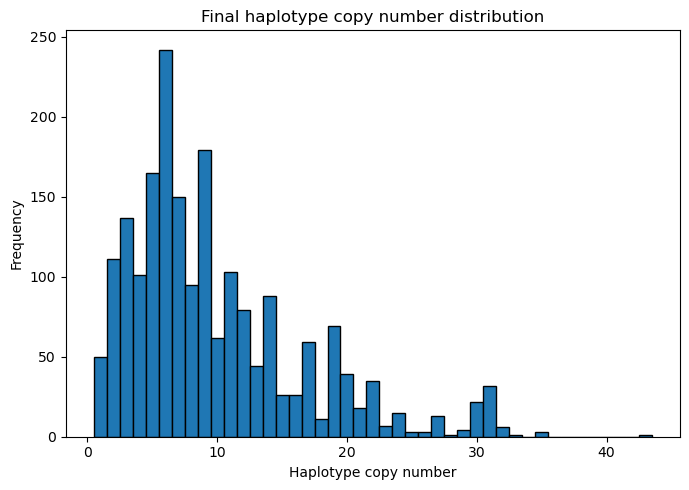

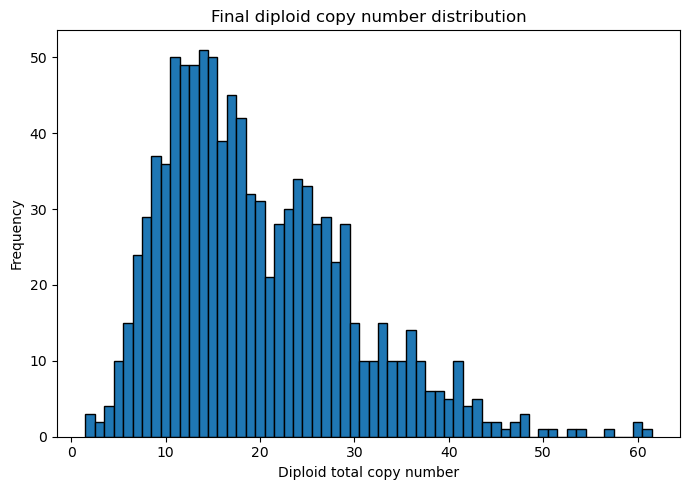


Running N=1000, rec=0.01 ...
Finished N=1000, rec=0.01

Running N=1000, rec=0.05 ...
Finished N=1000, rec=0.05

Running N=5000, rec=0.01 ...
Finished N=5000, rec=0.01

Running N=5000, rec=0.05 ...
Finished N=5000, rec=0.05

Replicate results (first 10 rows):
      N   rec  replicate      mode  generations  init_copies  mean_hap  \
0  1000  0.01          0  gaussian         1000           10   10.8815   
1  1000  0.01          1  gaussian         1000           10   19.1270   
2  1000  0.01          2  gaussian         1000           10    6.7865   
3  1000  0.01          3  gaussian         1000           10   10.8835   
4  1000  0.01          4  gaussian         1000           10   17.6420   
5  1000  0.01          5  gaussian         1000           10   15.8910   
6  1000  0.01          6  gaussian         1000           10   11.0710   
7  1000  0.01          7  gaussian         1000           10    9.9510   
8  1000  0.01          8  gaussian         1000           10    5.0970   


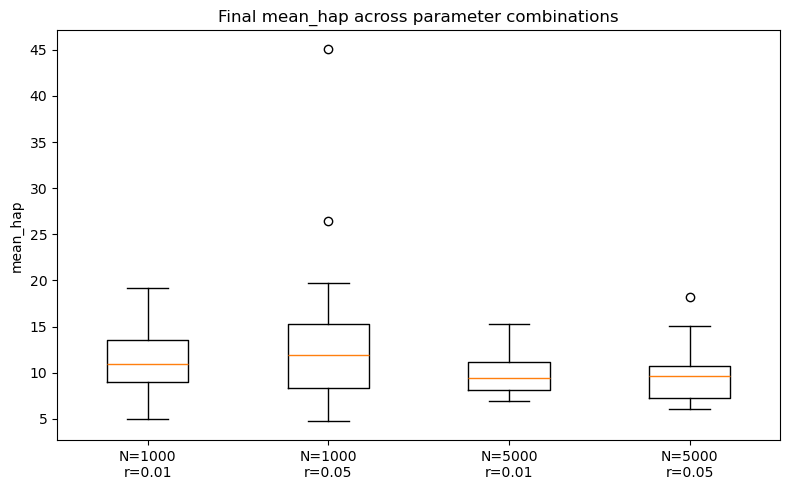

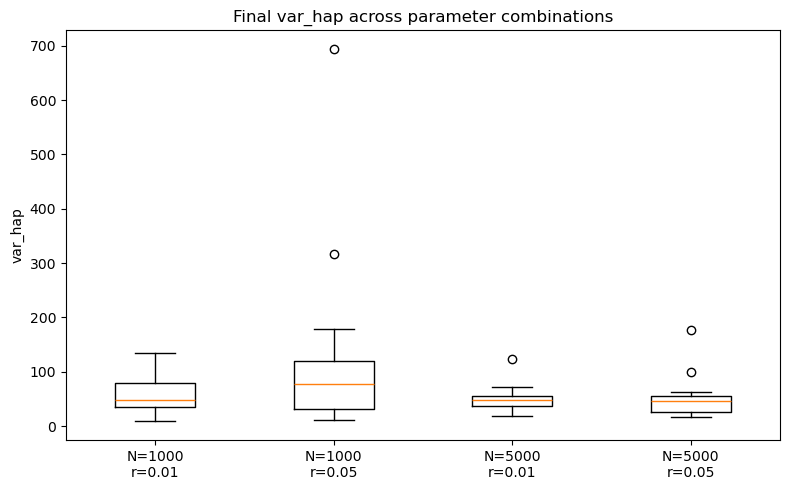

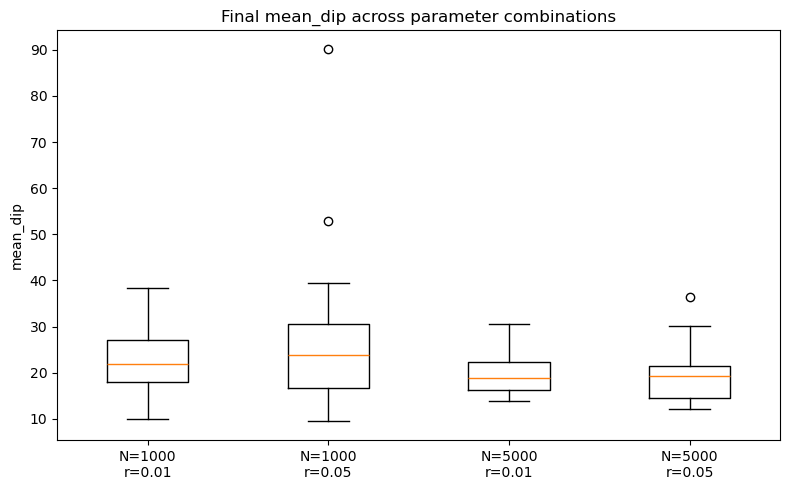

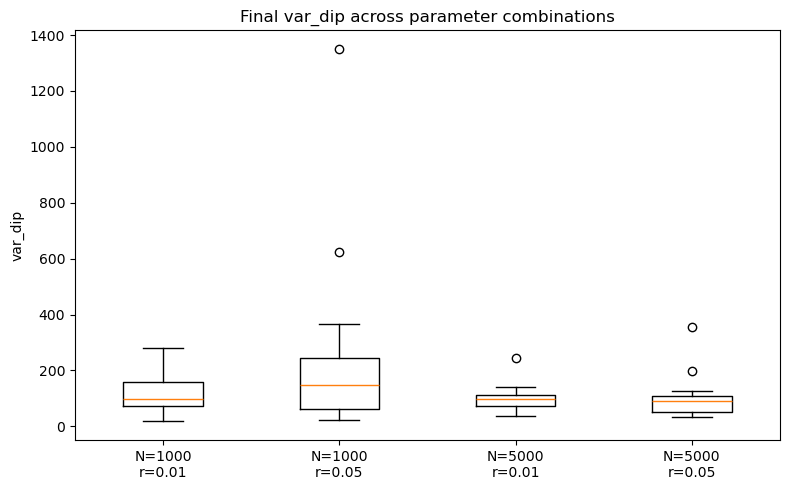


Saved replicate results to neutral_cnv_replicates_results.csv


In [34]:
def main():
    # --------------------------
    # Single-run example
    # --------------------------
    N = 1000
    init_copies = 10
    rec = 0.05
    generations = 500
    seed = 42
    record_every = 50
    mode = "gaussian"

    pop, history = simulate(
        N=N,
        init_copies=init_copies,
        rec=rec,
        generations=generations,
        seed=seed,
        record_every=record_every,
        mode=mode,
        init_sd=2.0,
    )

    print("Single-run history:\n")
    print_history(history)

    print("\nFinal population (first 10 individuals):")
    print(pop.hap_counts[:10])

    plot_final_distributions(pop)

    # --------------------------
    # Replicate grid
    # --------------------------
    Ns = [1000, 5000]
    recs = [0.01, 0.05]
    replicates = 20   # first test with 20; later change to 100
    generations_grid = 1000

    df = run_parameter_grid(
        Ns=Ns,
        recs=recs,
        replicates=replicates,
        generations=generations_grid,
        init_copies=10,
        mode="gaussian",
        init_sd=2.0,
        seed_base=12345,
    )

    print("\nReplicate results (first 10 rows):")
    print(df.head(10))

    print("\nSummary by parameter combination:")
    print(summarize_results(df))

    plot_box_by_group(df, "mean_hap")
    plot_box_by_group(df, "var_hap")
    plot_box_by_group(df, "mean_dip")
    plot_box_by_group(df, "var_dip")

    # optional: save results
    df.to_csv("neutral_cnv_replicates_results.csv", index=False)
    print("\nSaved replicate results to neutral_cnv_replicates_results.csv")


if __name__ == "__main__":
    main()

In [36]:
df = pd.read_csv("neutral_cnv_replicates_results.csv")
print(df.head())

      N   rec  replicate      mode  generations  init_copies  mean_hap  \
0  1000  0.01          0  gaussian         1000           10   10.8815   
1  1000  0.01          1  gaussian         1000           10   19.1270   
2  1000  0.01          2  gaussian         1000           10    6.7865   
3  1000  0.01          3  gaussian         1000           10   10.8835   
4  1000  0.01          4  gaussian         1000           10   17.6420   

      var_hap  min_hap  max_hap  mean_dip     var_dip  min_dip  max_dip  
0   46.787852        1       35    21.763   91.564395        2       53  
1  134.979361        1       50    38.254  279.382867        6       84  
2   17.936886        1       21    13.573   34.142814        2       33  
3   35.431644        1       31    21.767   66.224936        4       51  
4   55.646659        3       49    35.284  116.750094        9       80  


In [42]:
def plot_mean_box(df, column="mean_hap", save_path=None):
    import matplotlib.pyplot as plt

    groups = []
    labels = []

    for N in sorted(df["N"].unique()):
        for rec in sorted(df["rec"].unique()):
            subset = df[(df["N"] == N) & (df["rec"] == rec)][column]
            groups.append(subset.values)
            labels.append(f"N={N}\nr={rec}")

    plt.figure(figsize=(8, 5))
    plt.boxplot(groups, tick_labels=labels)
    plt.ylabel(column)
    plt.title(f"{column} across replicates")
    plt.tight_layout()

    if save_path is not None:
        plt.savefig(save_path, dpi=300)

    plt.show()

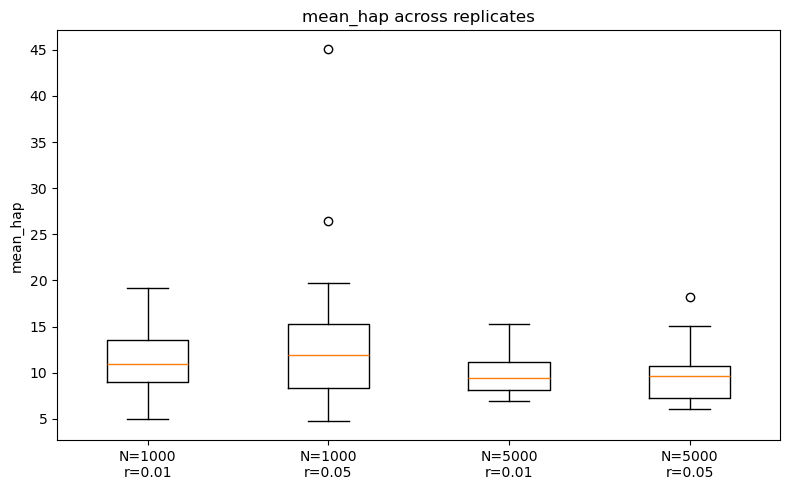

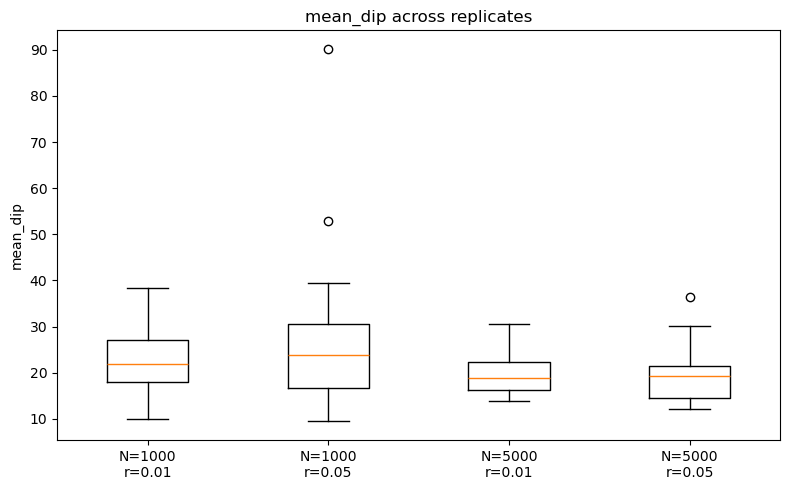

In [43]:
plot_mean_box(df, "mean_hap", save_path="mean_hap_boxplot.pdf")
plot_mean_box(df, "mean_dip", save_path="mean_dip_boxplot.pdf")